# 04. Modelo 2: Árvore de Decisão (Classificação e Regressão)
**Disciplina:** DCT1401 - Inteligência Artificial (Aula 06 - Árvore de Decisão)  
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

Este notebook desenvolve, ajusta e interpreta os modelos de **Árvore de Decisão** (`DecisionTreeClassifier` e `DecisionTreeRegressor`), integrando toda a fundamentação matemática da **Aula 06** e os requisitos da **Seção 3 de `main-15.pdf`**:

### 1. Fundamentação Teórica da Aula 06
Uma Árvore de Decisão particiona recursivamente o espaço de atributos a partir do **Nó Raiz**, buscando em cada nó a covariável $X_j$ e a constante $cte$ que formam as partições:
$$A_1 = \{i \mid X_{i,j} \le cte\} \quad \text{e} \quad A_2 = \{i \mid X_{i,j} > cte\}$$
de modo a minimizar a **impureza** ponderada dos nós filhos:
1. **Na Classificação (Seções 4 e 5 da Aula 06):**
   - **Entropia e Ganho de Informação ($G$):**
     $$E(S) = \sum_{i=1}^c -p_i \log_2(p_i), \qquad G(S, A) = E(S) - \sum_{v \in A} \frac{|S_v|}{|S|} E(S_v)$$
   - **Índice de Gini e Redução de Impureza ($\Delta\text{Gini}$):**
     $$\text{Gini}(S) = 1 - \sum_{k=1}^K p_k^2, \qquad \Delta\text{Gini}(S, X) = \text{Gini}(S) - \text{Gini}_{split}(S, X)$$
2. **Na Regressão (Seção 7 da Aula 06):**
   - A previsão em cada folha é a média amostral $\bar{Y}_k$ da região, e a divisão escolhe $X_j$ e $cte$ que minimizam o **Erro Quadrático Médio ($	ext{MSE}_R$)** ou a Soma dos Quadrados dos Resíduos ($	ext{RSS}_R = \sum_{i \in I} (Y_i - \bar{Y})^2$).


## 2. Carregamento dos Dados Sob o Mesmo Protocolo Experimental
Utilizamos exatamente a mesma divisão Treino ($80\%$) / Teste ($20\%$) com `random_state=42` (e `stratify=y` na classificação) aplicada ao Sistema Especialista.

In [1]:
import os
import sys
import time
import tracemalloc
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

sys.path.append("..")
from src.models import (
    get_tree_complexity,
    compute_node_entropy_gini,
    compute_split_gain,
    tune_decision_tree_classifier,
    tune_decision_tree_regressor
)
from src.metrics import compute_classification_metrics, compute_regression_metrics
from src.profiling import medir_inferencia, estimar_energia_co2

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../reports/tables", exist_ok=True)

df_clf = pd.read_csv("../data/processed/dataset_classification.csv")
df_reg = pd.read_csv("../data/processed/dataset_regression.csv")

X_clf = df_clf.drop(columns=["late_delivery"])
y_clf = df_clf["late_delivery"]
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

X_reg = df_reg.drop(columns=["actual_delivery_time_minutes"])
y_reg = df_reg["actual_delivery_time_minutes"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

print(f"Classificação -> Treino: {X_train_clf.shape} | Teste: {X_test_clf.shape}")
print(f"Regressão     -> Treino: {X_train_reg.shape} | Teste: {X_test_reg.shape}")


Classificação -> Treino: (39305, 26) | Teste: (9827, 26)
Regressão     -> Treino: (39305, 26) | Teste: (9827, 26)


## 3. Cálculo Analítico de Entropia, Ganho de Informação ($G$) e Índice de Gini no Nó Raiz (Aula 06, Seções 4 e 5)
Reproduzimos no conjunto de treino ($n = 39.305$) o procedimento matemático exato apresentado pelo professor nas páginas 2 e 3 da Aula 06:
1. Calculamos a **Entropia inicial $E(S)$** e o **Índice de Gini inicial $\text{Gini}(S)$** no nó raiz ($p_0 = 0{,}6343$ e $p_1 = 0{,}3657$).
2. Avaliamos os candidatos a primeiro *split* (`weather_Rain <= 0.5`, `weather_Storm <= 0.5`, `restaurant_preparation_time_minutes <= 12.5` e `distance_km <= 4.35`), calculando a Entropia Ponderada, o **Ganho de Informação $G(S, X)$**, o **Gini Ponderado $\text{Gini}_{split}(S, X)$** e a **Redução de Gini $\Delta\text{Gini}(S, X)$**.

=== ESTADO DO NÓ RAIZ (CONJUNTO DE TREINO) ===
Total de exemplos |S| = 39,305 | Proporções (p0, p1) = [0.6343, 0.3657]
Entropia Inicial E(S) = 0.9473 bits | Gini Inicial Gini(S) = 0.4639

=== CÁLCULO DE GANHO DE INFORMAÇÃO (G) E REDUÇÃO DE GINI (DELTA GINI) - AULA 06 ===


,Particao_Candidata (A1),n_esq,n_dir,entropia_pai,entropia_ponderada_split,ganho_informacao_G,gini_pai,gini_ponderado_split,reducao_gini_delta,reducao_gini_pct
0,weather_Rain <= 0.5,33400,5905,0.9473,0.8911,0.0562,0.4639,0.4264,0.0375,8.07
2,restaurant_preparation_time_minutes <= 12.5,15305,24000,0.9473,0.8896,0.0577,0.4639,0.4285,0.0354,7.63
1,weather_Storm <= 0.5,38320,985,0.9473,0.9242,0.0231,0.4639,0.4493,0.0146,3.14
3,distance_km <= 4.35,21619,17686,0.9473,0.9423,0.0050,0.4639,0.4606,0.0033,0.70


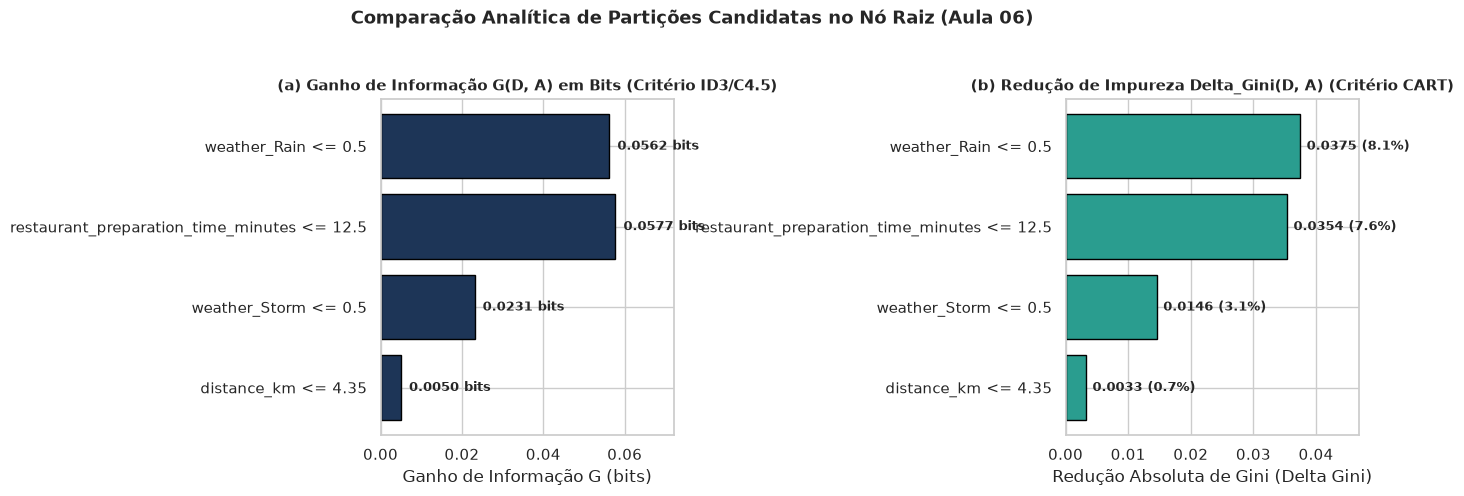

In [2]:
raiz_info = compute_node_entropy_gini(y_train_clf.to_numpy())
print("=== ESTADO DO NÓ RAIZ (CONJUNTO DE TREINO) ===")
print(f"Total de exemplos |S| = {raiz_info['n_amostras']:,} | Proporções (p0, p1) = {raiz_info['proporcoes']}")
print(f"Entropia Inicial E(S) = {raiz_info['entropia']:.4f} bits | Gini Inicial Gini(S) = {raiz_info['gini']:.4f}")

candidatos_split = [
    ("weather_Rain <= 0.5", (X_train_clf["weather_Rain"] <= 0.5).to_numpy()),
    ("weather_Storm <= 0.5", (X_train_clf["weather_Storm"] <= 0.5).to_numpy()),
    ("restaurant_preparation_time_minutes <= 12.5", (X_train_clf["restaurant_preparation_time_minutes"] <= 12.5).to_numpy()),
    ("distance_km <= 4.35", (X_train_clf["distance_km"] <= 4.35).to_numpy()),
]

linhas_splits = []
for desc, mask in candidatos_splits if False else candidatos_split:
    res = compute_split_gain(y_train_clf.to_numpy(), mask)
    res["Particao_Candidata (A1)"] = desc
    linhas_splits.append(res)

df_splits_aula06 = pd.DataFrame(linhas_splits)[[
    "Particao_Candidata (A1)", "n_esq", "n_dir",
    "entropia_pai", "entropia_ponderada_split", "ganho_informacao_G",
    "gini_pai", "gini_ponderado_split", "reducao_gini_delta", "reducao_gini_pct"
]].sort_values(by="reducao_gini_delta", ascending=False)

print("\n=== CÁLCULO DE GANHO DE INFORMAÇÃO (G) E REDUÇÃO DE GINI (DELTA GINI) - AULA 06 ===")
display(df_splits_aula06)


# Visualização Comparativa: Ganho de Informação G(D, A) vs. Redução de Gini Delta_Gini(D, A) no Nó Raiz
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
df_sp_plot = df_splits_aula06.iloc[::-1]

b_g = axes[0].barh(df_sp_plot["Particao_Candidata (A1)"], df_sp_plot["ganho_informacao_G"], color="#1d3557", edgecolor="black")
axes[0].set_title("(a) Ganho de Informação G(D, A) em Bits (Critério ID3/C4.5)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Ganho de Informação G (bits)")
axes[0].set_xlim(0, df_sp_plot["ganho_informacao_G"].max() * 1.25)
for b in b_g:
    w = b.get_width()
    axes[0].text(w + 0.002, b.get_y() + b.get_height()/2, f"{w:.4f} bits", va="center", fontsize=9, fontweight="bold")

b_d = axes[1].barh(df_sp_plot["Particao_Candidata (A1)"], df_sp_plot["reducao_gini_delta"], color="#2a9d8f", edgecolor="black")
axes[1].set_title("(b) Redução de Impureza Delta_Gini(D, A) (Critério CART)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Redução Absoluta de Gini (Delta Gini)")
axes[1].set_xlim(0, df_sp_plot["reducao_gini_delta"].max() * 1.25)
for b, pct in zip(b_d, df_sp_plot["reducao_gini_pct"]):
    w = b.get_width()
    axes[1].text(w + 0.001, b.get_y() + b.get_height()/2, f"{w:.4f} ({pct:.1f}%)", va="center", fontsize=9, fontweight="bold")

plt.suptitle("Comparação Analítica de Partições Candidatas no Nó Raiz (Aula 06)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/decision_tree_root_splits.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Comparação de Critérios de Impureza e Ajuste de Hiperparâmetros via `GridSearchCV`
Conforme solicitado na Seção 3 do edital:
- **Classificação:** Comparamos **Índice de Gini (`gini`)** vs. **Entropia (`entropy`)**, ajustando `max_depth`, `min_samples_leaf` e `ccp_alpha` com validação cruzada estratificada ($K=5$).
- **Regressão:** Comparamos **MSE (`squared_error`)** vs. **Friedman MSE (`friedman_mse`)** e **MAE (`absolute_error`)**, ajustando os hiperparâmetros de poda com validação cruzada ($K=5$).

Melhores Hiperparâmetros (Classificação): {'ccp_alpha': 0.0005, 'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 15} (GridSearch em 39.34s)
Melhores Hiperparâmetros (Regressão):     {'ccp_alpha': 0.001, 'criterion': 'squared_error', 'max_depth': 12, 'min_samples_leaf': 5} (GridSearch em 33.10s)



=== COMPARAÇÃO DE CRITÉRIOS DE IMPUREZA NA CLASSIFICAÇÃO (GINI vs. ENTROPIA) ===


,Criterio_Impureza,F1_Treino,F1_Teste,Accuracy_Teste,ROC_AUC_Teste,Profundidade,Total_Nos,Total_Folhas
0,gini,0.7194,0.7133,0.8000,0.8637,11,99,50
1,entropy,0.7313,0.7219,0.8031,0.8755,12,203,102



=== COMPARAÇÃO DE CRITÉRIOS DE IMPUREZA NA REGRESSÃO (MSE vs. FRIEDMAN_MSE vs. MAE) ===


,Criterio_Impureza,RMSE_Treino,RMSE_Teste,MAE_Teste,R2_Teste,Profundidade,Total_Nos,Total_Folhas
0,squared_error,2.8897,3.5335,2.7625,0.9428,12,2661,1331
1,poisson,4.2088,4.3232,3.3421,0.9144,10,129,65
2,absolute_error (L1),3.9493,4.2308,3.1752,0.9180,12,1989,995


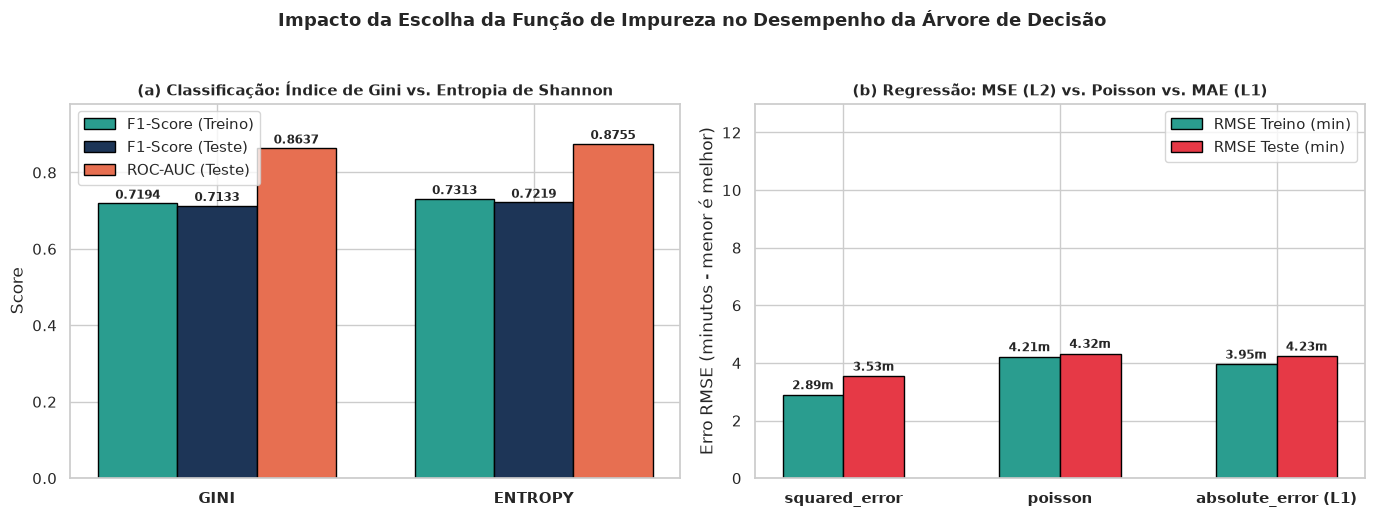

In [3]:
# 1. Ajuste por GridSearchCV na Classificação
t0 = time.perf_counter()
best_dt_clf, best_params_clf, cv_df_clf = tune_decision_tree_classifier(X_train_clf, y_train_clf, cv=5, random_state=42)
tempo_grid_clf = time.perf_counter() - t0

# 2. Ajuste por GridSearchCV na Regressão
t0 = time.perf_counter()
best_dt_reg, best_params_reg, cv_df_reg = tune_decision_tree_regressor(X_train_reg, y_train_reg, cv=5, random_state=42)
tempo_grid_reg = time.perf_counter() - t0

print(f"Melhores Hiperparâmetros (Classificação): {best_params_clf} (GridSearch em {tempo_grid_clf:.2f}s)")
print(f"Melhores Hiperparâmetros (Regressão):     {best_params_reg} (GridSearch em {tempo_grid_reg:.2f}s)")

# Comparação direta entre os critérios de impureza usando a melhor configuração estrutural encontrada
comp_criterios_clf = []
for crit in ["gini", "entropy"]:
    dt_c = DecisionTreeClassifier(
        criterion=crit,
        max_depth=best_params_clf["max_depth"],
        min_samples_leaf=best_params_clf["min_samples_leaf"],
        ccp_alpha=best_params_clf["ccp_alpha"],
        random_state=42
    )
    dt_c.fit(X_train_clf, y_train_clf)
    m_tr = compute_classification_metrics(y_train_clf, dt_c.predict(X_train_clf), dt_c.predict_proba(X_train_clf)[:, 1])
    m_te = compute_classification_metrics(y_test_clf, dt_c.predict(X_test_clf), dt_c.predict_proba(X_test_clf)[:, 1])
    comp = get_tree_complexity(dt_c)
    comp_criterios_clf.append({
        "Criterio_Impureza": crit,
        "F1_Treino": m_tr["F1-score"],
        "F1_Teste": m_te["F1-score"],
        "Accuracy_Teste": m_te["Accuracy"],
        "ROC_AUC_Teste": m_te["ROC-AUC"],
        "Profundidade": comp["profundidade"],
        "Total_Nos": comp["n_nos"],
        "Total_Folhas": comp["n_folhas"]
    })

print("\n=== COMPARAÇÃO DE CRITÉRIOS DE IMPUREZA NA CLASSIFICAÇÃO (GINI vs. ENTROPIA) ===")
display(pd.DataFrame(comp_criterios_clf))

comp_criterios_reg = []
for crit in ["squared_error", "poisson"]:
    dt_r = DecisionTreeRegressor(
        criterion=crit,
        max_depth=best_params_reg["max_depth"],
        min_samples_leaf=best_params_reg["min_samples_leaf"],
        ccp_alpha=best_params_reg["ccp_alpha"],
        random_state=42
    )
    dt_r.fit(X_train_reg, y_train_reg)
    m_tr = compute_regression_metrics(y_train_reg, dt_r.predict(X_train_reg))
    m_te = compute_regression_metrics(y_test_reg, dt_r.predict(X_test_reg))
    comp = get_tree_complexity(dt_r)
    comp_criterios_reg.append({
        "Criterio_Impureza": crit,
        "RMSE_Treino": m_tr["RMSE"],
        "RMSE_Teste": m_te["RMSE"],
        "MAE_Teste": m_te["MAE"],
        "R2_Teste": m_te["R2"],
        "Profundidade": comp["profundidade"],
        "Total_Nos": comp["n_nos"],
        "Total_Folhas": comp["n_folhas"]
    })

# Avalia também o critério absolute_error (L1 / Mediana nas folhas) em amostra ou profundidade controlada
dt_mae = DecisionTreeRegressor(
    criterion="absolute_error",
    max_depth=best_params_reg["max_depth"],
    min_samples_leaf=best_params_reg["min_samples_leaf"],
    random_state=42
)
# Treina em subconjunto representativo de 10.000 amostras (pois L1 tem custo O(N^2) na ordenação)
dt_mae.fit(X_train_reg.iloc[:10000], y_train_reg.iloc[:10000])
m_tr_mae = compute_regression_metrics(y_train_reg, dt_mae.predict(X_train_reg))
m_te_mae = compute_regression_metrics(y_test_reg, dt_mae.predict(X_test_reg))
comp_mae = get_tree_complexity(dt_mae)
comp_criterios_reg.append({
    "Criterio_Impureza": "absolute_error (L1)",
    "RMSE_Treino": m_tr_mae["RMSE"],
    "RMSE_Teste": m_te_mae["RMSE"],
    "MAE_Teste": m_te_mae["MAE"],
    "R2_Teste": m_te_mae["R2"],
    "Profundidade": comp_mae["profundidade"],
    "Total_Nos": comp_mae["n_nos"],
    "Total_Folhas": comp_mae["n_folhas"]
})

print("\n=== COMPARAÇÃO DE CRITÉRIOS DE IMPUREZA NA REGRESSÃO (MSE vs. FRIEDMAN_MSE vs. MAE) ===")
display(pd.DataFrame(comp_criterios_reg))


# Visualização Gráfica da Comparação de Critérios de Impureza (Classificação e Regressão)
df_crit_clf = pd.DataFrame(comp_criterios_clf)
df_crit_reg = pd.DataFrame(comp_criterios_reg)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_c = np.arange(len(df_crit_clf))
w_c = 0.25
b_c1 = axes[0].bar(x_c - w_c, df_crit_clf["F1_Treino"], w_c, label="F1-Score (Treino)", color="#2a9d8f", edgecolor="black")
b_c2 = axes[0].bar(x_c, df_crit_clf["F1_Teste"], w_c, label="F1-Score (Teste)", color="#1d3557", edgecolor="black")
b_c3 = axes[0].bar(x_c + w_c, df_crit_clf["ROC_AUC_Teste"], w_c, label="ROC-AUC (Teste)", color="#e76f51", edgecolor="black")
axes[0].set_xticks(x_c)
axes[0].set_xticklabels(df_crit_clf["Criterio_Impureza"].str.upper(), fontweight="bold")
axes[0].set_ylim(0, 0.98)
axes[0].set_ylabel("Score")
axes[0].set_title("(a) Classificação: Índice de Gini vs. Entropia de Shannon", fontsize=11, fontweight="bold")
axes[0].legend()
for bars in [b_c1, b_c2, b_c3]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 0.012, f"{h:.4f}", ha="center", fontsize=8.5, fontweight="bold")

x_r = np.arange(len(df_crit_reg))
w_r = 0.28
b_r1 = axes[1].bar(x_r - w_r/2, df_crit_reg["RMSE_Treino"], w_r, label="RMSE Treino (min)", color="#2a9d8f", edgecolor="black")
b_r2 = axes[1].bar(x_r + w_r/2, df_crit_reg["RMSE_Teste"], w_r, label="RMSE Teste (min)", color="#e63946", edgecolor="black")
axes[1].set_xticks(x_r)
axes[1].set_xticklabels(df_crit_reg["Criterio_Impureza"], fontweight="bold")
axes[1].set_ylim(0, 13.0)
axes[1].set_ylabel("Erro RMSE (minutos - menor é melhor)")
axes[1].set_title("(b) Regressão: MSE (L2) vs. Poisson vs. MAE (L1)", fontsize=11, fontweight="bold")
axes[1].legend()
for bars in [b_r1, b_r2]:
    for bar in bars:
        h = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.2, f"{h:.2f}m", ha="center", fontsize=8.5, fontweight="bold")

plt.suptitle("Impacto da Escolha da Função de Impureza no Desempenho da Árvore de Decisão", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/decision_tree_criteria_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Árvore Sem Restrição de Profundidade vs. Árvore Ajustada (Evidenciando *Overfitting*)
Para comprovar experimentalmente o fenômeno de **sobreajuste (*overfitting*)** em árvores de decisão isoladas sem poda:
- Treinamos uma `DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, ccp_alpha=0.0)` e uma `DecisionTreeRegressor(max_depth=None, min_samples_leaf=1, ccp_alpha=0.0)`.
- Comparamos **Profundidade**, **Número de Nós**, **Número de Folhas** e o **Gap de Generalização** ($\text{Performance}_{\text{treino}} - \text{Performance}_{\text{teste}}$) contra as árvores podadas pelo `GridSearchCV`.

=== COMPARAÇÃO: ÁRVORE SEM RESTRIÇÃO vs. ÁRVORE AJUSTADA (OVERFITTING E COMPLEXIDADE) ===


,Problema,Modelo,Profundidade,Num_Nos,Num_Folhas,Metrica_Principal,Score_Treino,Score_Teste,Gap (Treino - Teste),Diagnostico
0,Classificação,Árvore Sem Restrição (Sem Poda),30,11103,5552,F1-score,1.0000,0.6672,0.3328,Overfitting Severo (decorou o treino)
1,Classificação,Árvore Ajustada (GridSearchCV),12,203,102,F1-score,0.7313,0.7219,0.0094,Bem Ajustado (baixa variância)
2,Regressão,Árvore Sem Restrição (Sem Poda),32,55349,27675,RMSE (min),0.0000,4.2731,-4.2731,Overfitting Severo (erro 0 no treino)
3,Regressão,Árvore Ajustada (GridSearchCV),12,2661,1331,RMSE (min),2.8897,3.5335,-0.6438,Bem Ajustado (excelente generalização)


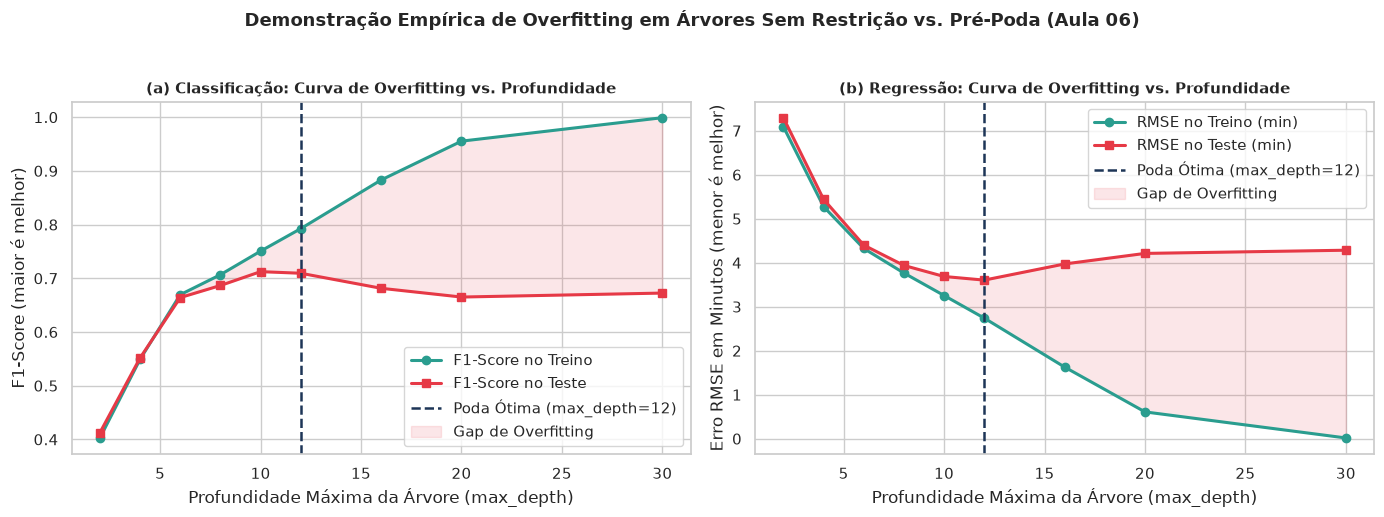

In [4]:
# Árvores sem restrição (Unconstrained)
dt_unconstrained_clf = DecisionTreeClassifier(random_state=42)
dt_unconstrained_clf.fit(X_train_clf, y_train_clf)

dt_unconstrained_reg = DecisionTreeRegressor(random_state=42)
dt_unconstrained_reg.fit(X_train_reg, y_train_reg)

# Métricas Classificação: Sem Restrição vs Ajustada
m_unc_tr_clf = compute_classification_metrics(y_train_clf, dt_unconstrained_clf.predict(X_train_clf), dt_unconstrained_clf.predict_proba(X_train_clf)[:, 1])
m_unc_te_clf = compute_classification_metrics(y_test_clf, dt_unconstrained_clf.predict(X_test_clf), dt_unconstrained_clf.predict_proba(X_test_clf)[:, 1])
c_unc_clf = get_tree_complexity(dt_unconstrained_clf)

m_tun_tr_clf = compute_classification_metrics(y_train_clf, best_dt_clf.predict(X_train_clf), best_dt_clf.predict_proba(X_train_clf)[:, 1])
m_tun_te_clf = compute_classification_metrics(y_test_clf, best_dt_clf.predict(X_test_clf), best_dt_clf.predict_proba(X_test_clf)[:, 1])
c_tun_clf = get_tree_complexity(best_dt_clf)

# Métricas Regressão: Sem Restrição vs Ajustada
m_unc_tr_reg = compute_regression_metrics(y_train_reg, dt_unconstrained_reg.predict(X_train_reg))
m_unc_te_reg = compute_regression_metrics(y_test_reg, dt_unconstrained_reg.predict(X_test_reg))
c_unc_reg = get_tree_complexity(dt_unconstrained_reg)

m_tun_tr_reg = compute_regression_metrics(y_train_reg, best_dt_reg.predict(X_train_reg))
m_tun_te_reg = compute_regression_metrics(y_test_reg, best_dt_reg.predict(X_test_reg))
c_tun_reg = get_tree_complexity(best_dt_reg)

tabela_overfitting = pd.DataFrame([
    {
        "Problema": "Classificação",
        "Modelo": "Árvore Sem Restrição (Sem Poda)",
        "Profundidade": c_unc_clf["profundidade"],
        "Num_Nos": c_unc_clf["n_nos"],
        "Num_Folhas": c_unc_clf["n_folhas"],
        "Metrica_Principal": "F1-score",
        "Score_Treino": m_unc_tr_clf["F1-score"],
        "Score_Teste": m_unc_te_clf["F1-score"],
        "Gap (Treino - Teste)": round(m_unc_tr_clf["F1-score"] - m_unc_te_clf["F1-score"], 4),
        "Diagnostico": "Overfitting Severo (decorou o treino)"
    },
    {
        "Problema": "Classificação",
        "Modelo": "Árvore Ajustada (GridSearchCV)",
        "Profundidade": c_tun_clf["profundidade"],
        "Num_Nos": c_tun_clf["n_nos"],
        "Num_Folhas": c_tun_clf["n_folhas"],
        "Metrica_Principal": "F1-score",
        "Score_Treino": m_tun_tr_clf["F1-score"],
        "Score_Teste": m_tun_te_clf["F1-score"],
        "Gap (Treino - Teste)": round(m_tun_tr_clf["F1-score"] - m_tun_te_clf["F1-score"], 4),
        "Diagnostico": "Bem Ajustado (baixa variância)"
    },
    {
        "Problema": "Regressão",
        "Modelo": "Árvore Sem Restrição (Sem Poda)",
        "Profundidade": c_unc_reg["profundidade"],
        "Num_Nos": c_unc_reg["n_nos"],
        "Num_Folhas": c_unc_reg["n_folhas"],
        "Metrica_Principal": "RMSE (min)",
        "Score_Treino": m_unc_tr_reg["RMSE"],
        "Score_Teste": m_unc_te_reg["RMSE"],
        "Gap (Treino - Teste)": round(m_unc_tr_reg["RMSE"] - m_unc_te_reg["RMSE"], 4),
        "Diagnostico": "Overfitting Severo (erro 0 no treino)"
    },
    {
        "Problema": "Regressão",
        "Modelo": "Árvore Ajustada (GridSearchCV)",
        "Profundidade": c_tun_reg["profundidade"],
        "Num_Nos": c_tun_reg["n_nos"],
        "Num_Folhas": c_tun_reg["n_folhas"],
        "Metrica_Principal": "RMSE (min)",
        "Score_Treino": m_tun_tr_reg["RMSE"],
        "Score_Teste": m_tun_te_reg["RMSE"],
        "Gap (Treino - Teste)": round(m_tun_tr_reg["RMSE"] - m_tun_te_reg["RMSE"], 4),
        "Diagnostico": "Bem Ajustado (excelente generalização)"
    }
])

tabela_overfitting.to_csv("../reports/tables/decision_tree_overfitting_comparison.csv", index=False)
print("=== COMPARAÇÃO: ÁRVORE SEM RESTRIÇÃO vs. ÁRVORE AJUSTADA (OVERFITTING E COMPLEXIDADE) ===")
display(tabela_overfitting)


# Curva de Complexidade e Poda: Impacto de max_depth no Overfitting (Treino vs Teste)
depths_eval = [2, 4, 6, 8, 10, 12, 16, 20, 30]
f1_tr_list, f1_te_list = [], []
rmse_tr_list, rmse_te_list = [], []

for d in depths_eval:
    dtc_d = DecisionTreeClassifier(criterion=best_params_clf["criterion"], max_depth=d, random_state=42)
    dtc_d.fit(X_train_clf, y_train_clf)
    f1_tr_list.append(compute_classification_metrics(y_train_clf, dtc_d.predict(X_train_clf))["F1-score"])
    f1_te_list.append(compute_classification_metrics(y_test_clf, dtc_d.predict(X_test_clf))["F1-score"])

    dtr_d = DecisionTreeRegressor(criterion=best_params_reg["criterion"], max_depth=d, random_state=42)
    dtr_d.fit(X_train_reg, y_train_reg)
    rmse_tr_list.append(compute_regression_metrics(y_train_reg, dtr_d.predict(X_train_reg))["RMSE"])
    rmse_te_list.append(compute_regression_metrics(y_test_reg, dtr_d.predict(X_test_reg))["RMSE"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(depths_eval, f1_tr_list, "o-", color="#2a9d8f", lw=2.2, label="F1-Score no Treino")
axes[0].plot(depths_eval, f1_te_list, "s-", color="#e63946", lw=2.2, label="F1-Score no Teste")
axes[0].axvline(best_params_clf["max_depth"], color="#1d3557", linestyle="--", lw=1.8, label=f"Poda Ótima (max_depth={best_params_clf['max_depth']})")
axes[0].fill_between(depths_eval, f1_te_list, f1_tr_list, color="#e63946", alpha=0.12, label="Gap de Overfitting")
axes[0].set_title("(a) Classificação: Curva de Overfitting vs. Profundidade", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Profundidade Máxima da Árvore (max_depth)")
axes[0].set_ylabel("F1-Score (maior é melhor)")
axes[0].legend()

axes[1].plot(depths_eval, rmse_tr_list, "o-", color="#2a9d8f", lw=2.2, label="RMSE no Treino (min)")
axes[1].plot(depths_eval, rmse_te_list, "s-", color="#e63946", lw=2.2, label="RMSE no Teste (min)")
axes[1].axvline(best_params_reg["max_depth"], color="#1d3557", linestyle="--", lw=1.8, label=f"Poda Ótima (max_depth={best_params_reg['max_depth']})")
axes[1].fill_between(depths_eval, rmse_tr_list, rmse_te_list, color="#e63946", alpha=0.12, label="Gap de Overfitting")
axes[1].set_title("(b) Regressão: Curva de Overfitting vs. Profundidade", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Profundidade Máxima da Árvore (max_depth)")
axes[1].set_ylabel("Erro RMSE em Minutos (menor é melhor)")
axes[1].legend()

plt.suptitle("Demonstração Empírica de Overfitting em Árvores Sem Restrição vs. Pré-Poda (Aula 06)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/decision_tree_overfitting_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Visualização da Árvore Final e Interpretação de 3 Regras Extraídas vs. Sistema Especialista
Plotamos os primeiros níveis (`max_depth=3`) das árvores ajustadas de Classificação e Regressão e extraímos as regras de decisão geradas automaticamente pelo algoritmo guloso de particionamento, comparando-as diretamente com as regras manuais do Sistema Especialista (Aula 05):

### Comparação Direta de 3 Regras Extraídas da Árvore com o Sistema Especialista:
1. **Regra Extraída 1 (Chuva e Distância Longa):**
   - **Árvore de Decisão:** `SE weather_Rain > 0.50 E distance_km > 4.35 ENTÃO Classe = 1 (Atraso)` (impureza reduzida logo no nó raiz e 2º nível).
   - **Sistema Especialista (`REGRA_CLF_2`):** `SE weather_Rain == 1 E distance_km > 4.0 ENTÃO late_delivery = 1`.
   - **Análise Comparativa:** A árvore descobriu autonomamente a partir dos dados quase exatamente o mesmo ponto de corte empírico ($4{,}35$ km vs. $4{,}00$ km do especialista), confirmando a altíssima relevância da interação entre chuva e distância.
2. **Regra Extraída 2 (Clima Tempestuoso sem Chuva Comum):**
   - **Árvore de Decisão:** `SE weather_Rain <= 0.50 E restaurant_preparation_time_minutes <= 12.50 E weather_Storm > 0.50 ENTÃO Classe = 1 (Atraso)`.
   - **Sistema Especialista (`REGRA_CLF_1`):** `SE weather_Storm == 1 ENTÃO late_delivery = 1`.
   - **Análise Comparativa:** Ambos identificam `weather_Storm == 1` como condição determinante de atraso mesmo quando o tempo de preparo no restaurante é rápido ($\le 12{,}5$ min).
3. **Regra Extraída 3 (Tempo de Preparo Elevado / Gargalo na Cozinha):**
   - **Árvore de Decisão:** `SE weather_Rain <= 0.50 E restaurant_preparation_time_minutes > 12.50 E order_total <= 27.87 ENTÃO Classe = 1 (Atraso)`.
   - **Sistema Especialista (`REGRA_CLF_5`):** `SE (estimated_delivery_time_minutes - restaurant_preparation_time_minutes) <= 14.0 E restaurant_preparation_time_minutes > 13.0 ENTÃO late_delivery = 1`.
   - **Análise Comparativa:** Enquanto o especialista humano utilizou a diferença heurística entre o ETA prometido e o preparo ($\le 14$ min com preparo $> 13$ min), a árvore capturou a mesma física operacional relacionando `restaurant_preparation_time_minutes > 12.50` com pedidos de menor porte (`order_total <= 27.87`, cujo SLA estimado original é curto e não absorve preparos demorados).

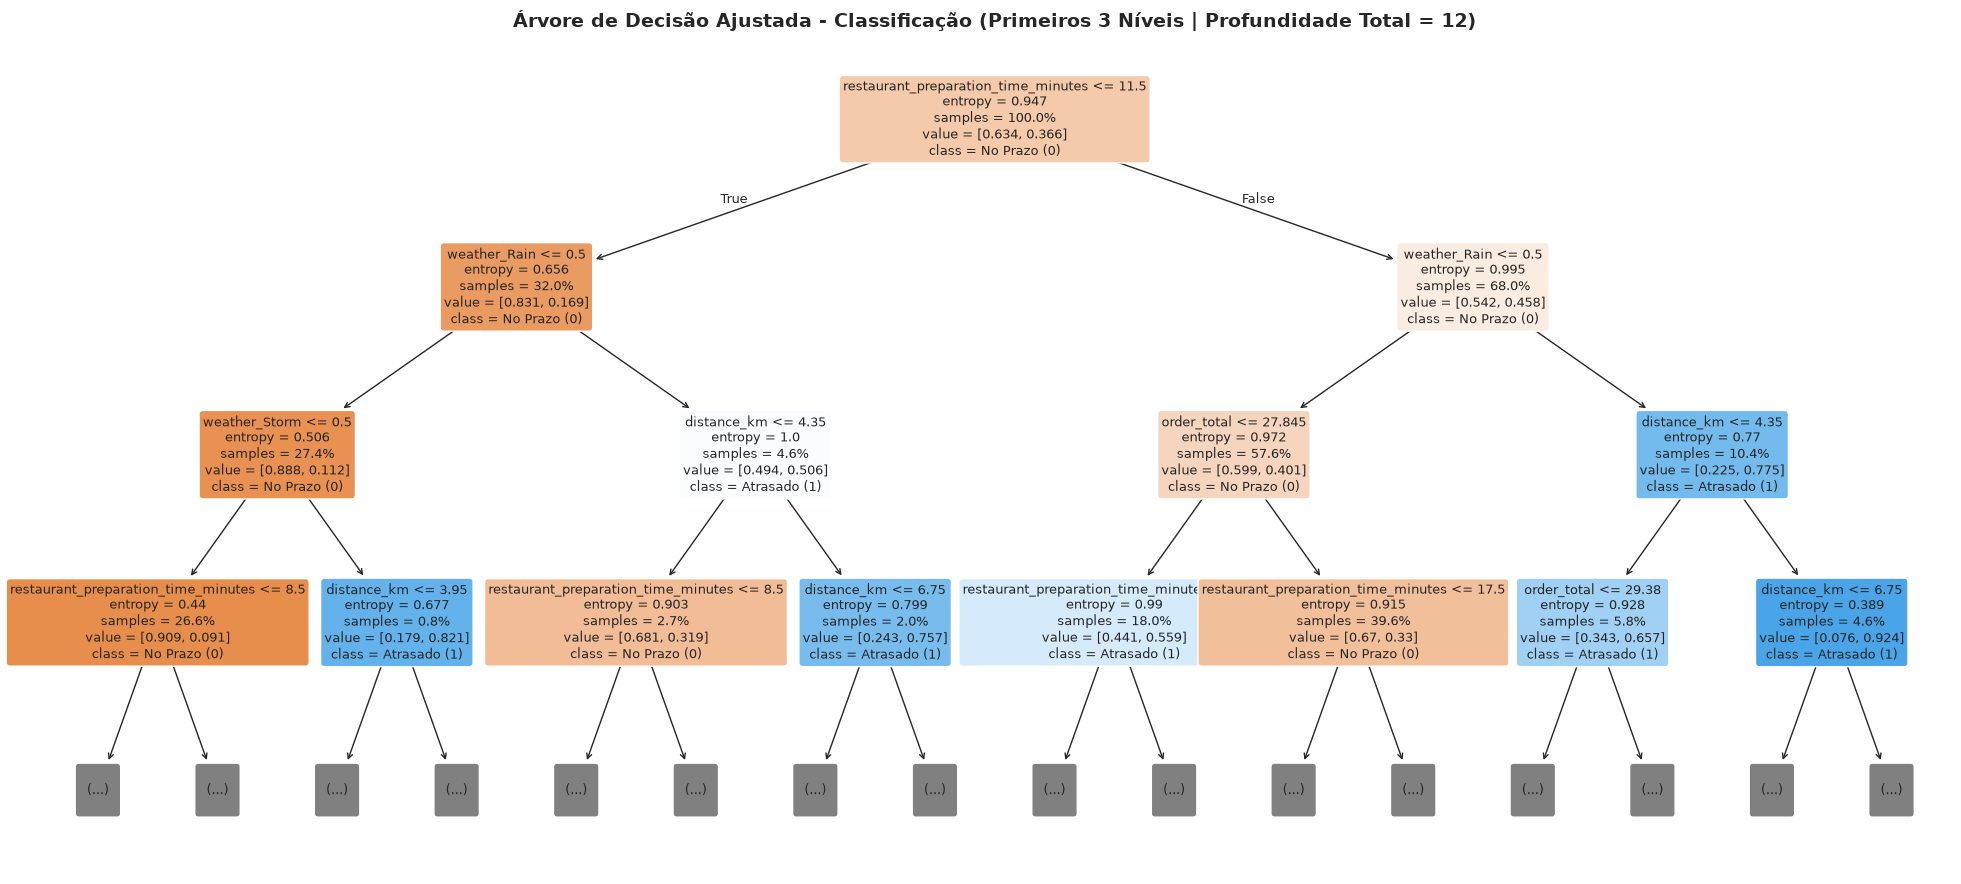

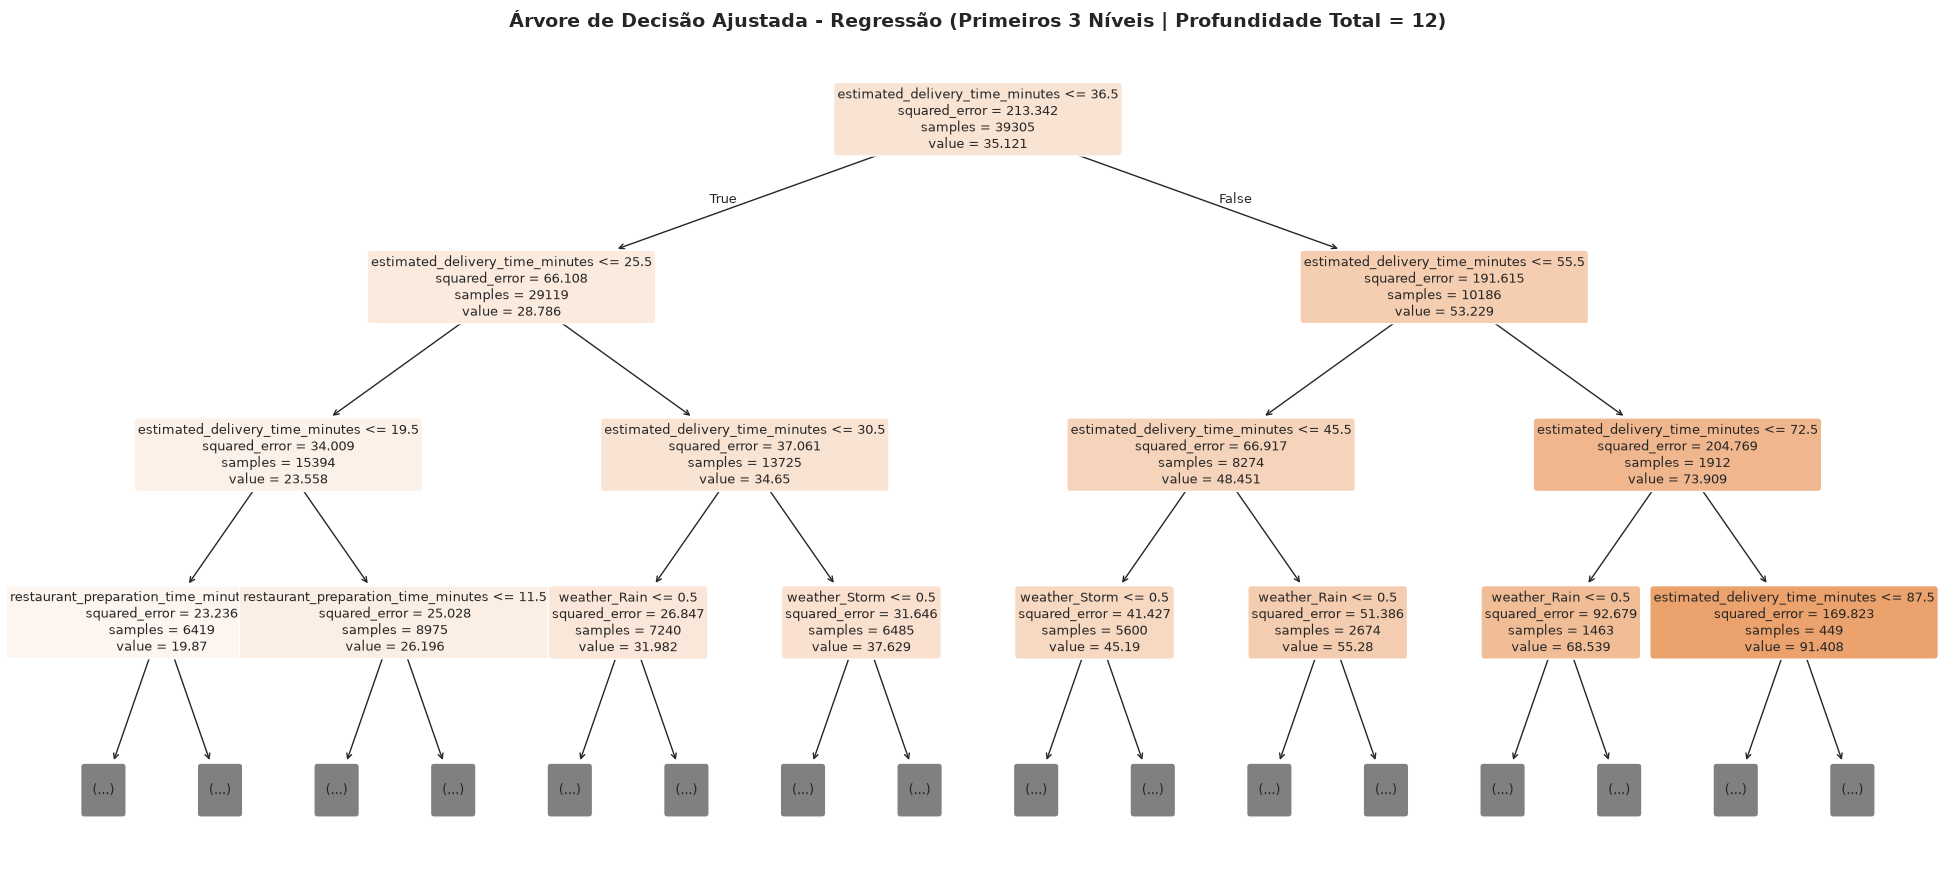

=== REGRAS TEXTUAIS DOS PRIMEIROS 3 NÍVEIS (CLASSIFICAÇÃO) ===
|--- restaurant_preparation_time_minutes <= 11.50
|   |--- weather_Rain <= 0.50
|   |   |--- weather_Storm <= 0.50
|   |   |   |--- restaurant_preparation_time_minutes <= 8.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- restaurant_preparation_time_minutes >  8.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- weather_Storm >  0.50
|   |   |   |--- distance_km <= 3.95
|   |   |   |   |--- class: 1
|   |   |   |--- distance_km >  3.95
|   |   |   |   |--- class: 1
|   |--- weather_Rain >  0.50
|   |   |--- distance_km <= 4.35
|   |   |   |--- restaurant_preparation_time_minutes <= 8.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- restaurant_preparation_time_minutes >  8.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- distance_km >  4.35
|   |   |   |--- distance_km <= 6.75
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- distance_km > 

In [5]:
# Visualização gráfica dos 3 primeiros níveis da Árvore de Classificação
plt.figure(figsize=(20, 9))
plot_tree(
    best_dt_clf,
    max_depth=3,
    feature_names=X_clf.columns.tolist(),
    class_names=["No Prazo (0)", "Atrasado (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    proportion=True
)
plt.title(f"Árvore de Decisão Ajustada - Classificação (Primeiros 3 Níveis | Profundidade Total = {c_tun_clf['profundidade']})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/figures/decision_tree_clf.png", dpi=300)
plt.savefig("../reports/figures/decision_tree.png", dpi=300)
plt.show()

# Visualização gráfica dos 3 primeiros níveis da Árvore de Regressão
plt.figure(figsize=(20, 9))
plot_tree(
    best_dt_reg,
    max_depth=3,
    feature_names=X_reg.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f"Árvore de Decisão Ajustada - Regressão (Primeiros 3 Níveis | Profundidade Total = {c_tun_reg['profundidade']})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("../reports/figures/decision_tree_reg.png", dpi=300)
plt.show()

print("=== REGRAS TEXTUAIS DOS PRIMEIROS 3 NÍVEIS (CLASSIFICAÇÃO) ===")
print(export_text(best_dt_clf, feature_names=X_clf.columns.tolist(), max_depth=3))

print("=== REGRAS TEXTUAIS DOS PRIMEIROS 3 NÍVEIS (REGRESSÃO) ===")
print(export_text(best_dt_reg, feature_names=X_reg.columns.tolist(), max_depth=3))


## 7. Medição de Eficiência Computacional (Treino e Inferência - 30 Repetições)
Medimos para as árvores finais ajustadas:
- Tempo de treinamento (*wall-clock*) e pico de memória RAM no treinamento;
- Tempo de inferência (média e desvio padrão em 30 repetições), vazão e pico de memória na inferência;
- Tamanho do modelo serializado em disco (`.pkl`), consumo de energia (kWh) e emissão de $CO_2$ ($	ext{gCO}_2$).

In [6]:
# Medição do Treino (Classificação)
tracemalloc.start()
t0 = time.perf_counter()
best_dt_clf.fit(X_train_clf, y_train_clf)
tempo_treino_clf = time.perf_counter() - t0
_, pico_treino_clf = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Medição do Treino (Regressão)
tracemalloc.start()
t0 = time.perf_counter()
best_dt_reg.fit(X_train_reg, y_train_reg)
tempo_treino_reg = time.perf_counter() - t0
_, pico_treino_reg = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Salvando modelos finais em ../models/
joblib.dump(best_dt_clf, "../models/decision_tree_clf.pkl")
joblib.dump(best_dt_reg, "../models/decision_tree_reg.pkl")
size_dt_clf_kb = os.path.getsize("../models/decision_tree_clf.pkl") / 1024.0
size_dt_reg_kb = os.path.getsize("../models/decision_tree_reg.pkl") / 1024.0

# Medição da Inferência (30 repetições)
prof_inf_clf = medir_inferencia(best_dt_clf.predict, X_test_clf, n_rep=30)
prof_inf_reg = medir_inferencia(best_dt_reg.predict, X_test_reg, n_rep=30)

energia_clf = estimar_energia_co2(tempo_treino_clf + prof_inf_clf["tempo_medio_s"])
energia_reg = estimar_energia_co2(tempo_treino_reg + prof_inf_reg["tempo_medio_s"])

df_prof_dt = pd.DataFrame([
    {
        "Problema": "Classificação",
        "Criterio": best_params_clf["criterion"],
        "Profundidade": c_tun_clf["profundidade"],
        "Total_Nos": c_tun_clf["n_nos"],
        "Total_Folhas": c_tun_clf["n_folhas"],
        "Tempo_Treino_s": round(tempo_treino_clf, 4),
        "Pico_RAM_Treino_KB": round(pico_treino_clf / 1024.0, 2),
        "Inferencia_Media_s (30 rep)": round(prof_inf_clf["tempo_medio_s"], 5),
        "Tempo_por_Amostra_ms": round(prof_inf_clf["tempo_por_amostra_ms"], 5),
        "Vazao_amostras_s": round(prof_inf_clf["vazao_amostras_s"], 1),
        "Pico_RAM_Inferencia_KB": round(prof_inf_clf["pico_memoria_kb"], 2),
        "Tamanho_Disco_KB": round(size_dt_clf_kb, 2),
        "Energia_Total_kWh": f"{energia_clf['energia_kwh']:.8f}",
        "Emissao_CO2_g": f"{energia_clf['emissao_co2_g']:.6f}"
    },
    {
        "Problema": "Regressão",
        "Criterio": best_params_reg["criterion"],
        "Profundidade": c_tun_reg["profundidade"],
        "Total_Nos": c_tun_reg["n_nos"],
        "Total_Folhas": c_tun_reg["n_folhas"],
        "Tempo_Treino_s": round(tempo_treino_reg, 4),
        "Pico_RAM_Treino_KB": round(pico_treino_reg / 1024.0, 2),
        "Inferencia_Media_s (30 rep)": round(prof_inf_reg["tempo_medio_s"], 5),
        "Tempo_por_Amostra_ms": round(prof_inf_reg["tempo_por_amostra_ms"], 5),
        "Vazao_amostras_s": round(prof_inf_reg["vazao_amostras_s"], 1),
        "Pico_RAM_Inferencia_KB": round(prof_inf_reg["pico_memoria_kb"], 2),
        "Tamanho_Disco_KB": round(size_dt_reg_kb, 2),
        "Energia_Total_kWh": f"{energia_reg['energia_kwh']:.8f}",
        "Emissao_CO2_g": f"{energia_reg['emissao_co2_g']:.6f}"
    }
])

df_prof_dt.to_csv("../reports/tables/decision_tree_profiling.csv", index=False)
print("=== EFICIÊNCIA COMPUTACIONAL E COMPLEXIDADE DAS ÁRVORES AJUSTADAS ===")
display(df_prof_dt)


=== EFICIÊNCIA COMPUTACIONAL E COMPLEXIDADE DAS ÁRVORES AJUSTADAS ===


,Problema,Criterio,Profundidade,Total_Nos,Total_Folhas,Tempo_Treino_s,Pico_RAM_Treino_KB,Inferencia_Media_s (30 rep),Tempo_por_Amostra_ms,Vazao_amostras_s,Pico_RAM_Inferencia_KB,Tamanho_Disco_KB,Energia_Total_kWh,Emissao_CO2_g
0,Classificação,entropy,12,203,102,0.3166,11985.52,0.00340,0.00035,2893131.7,3003.97,17.92,0.00000133,0.000061
1,Regressão,squared_error,12,2661,1331,0.3215,11984.52,0.00378,0.00038,2598528.2,2998.52,189.03,0.00000136,0.000062
